In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("../data/Mall_Customers.csv")

df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [8]:
df.rename(columns={
    'Genre':'Gender',
    'Annual Income (k$)':'Income',
    'Spending Score (1-100)':'Score'
}, inplace=True)

df.head()

,CustomerID,Gender,Age,Income,Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Univariate Analysis** :- Univariate analysis is the simplest form of quantitative data analysis, examining a single variable at a time to describe its distribution, central tendency, and spread.

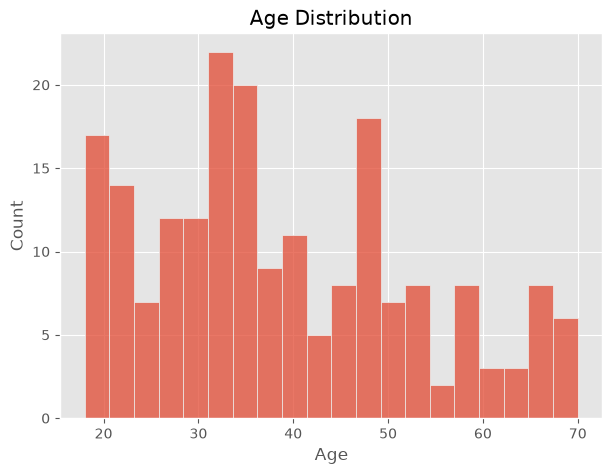

In [9]:
plt.figure(figsize=(7,5))

sns.histplot(df['Age'], bins=20)

plt.title("Age Distribution")

plt.show()

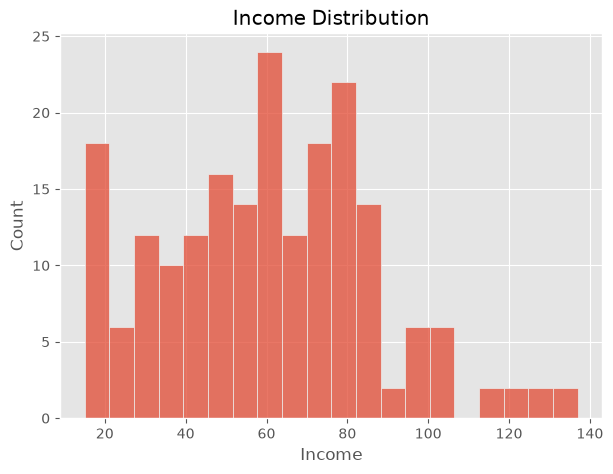

In [10]:
plt.figure(figsize=(7,5))

sns.histplot(df['Income'], bins=20)

plt.title("Income Distribution")

plt.show()

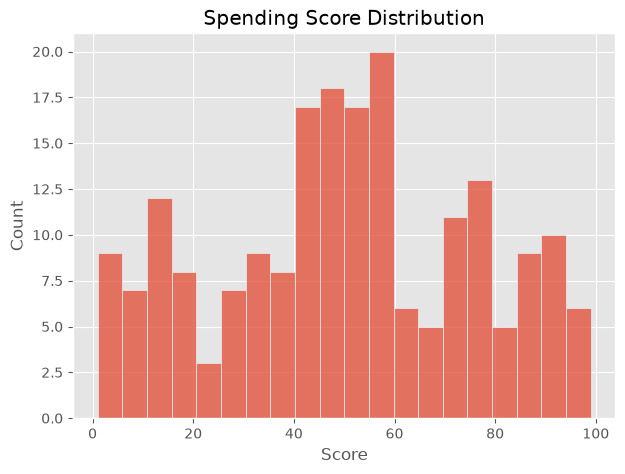

In [11]:
plt.figure(figsize=(7,5))

sns.histplot(df['Score'], bins=20)

plt.title("Spending Score Distribution")

plt.show()

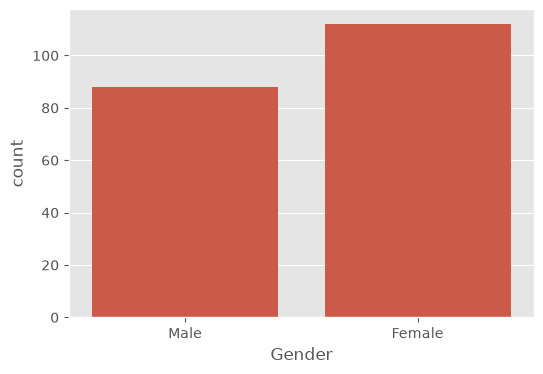

In [12]:
plt.figure(figsize=(6,4))

sns.countplot(data=df,x='Gender')

plt.show()

**Boxplots**

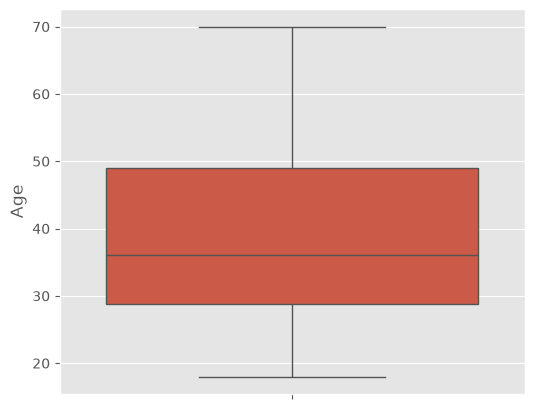

In [13]:
plt.figure(figsize=(6,5))

sns.boxplot(y=df['Age'])

plt.show()

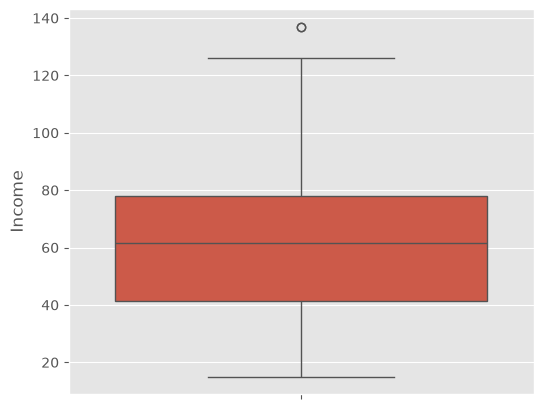

In [14]:
plt.figure(figsize=(6,5))

sns.boxplot(y=df['Income'])

plt.show()

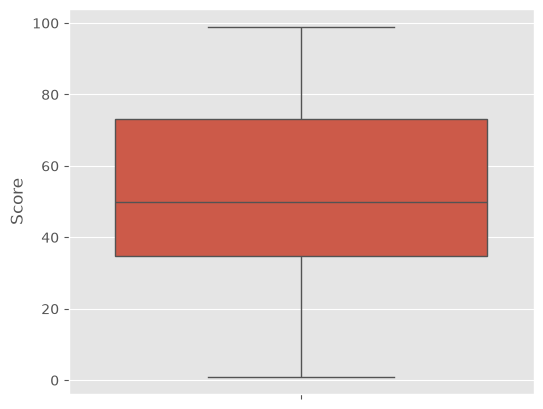

In [15]:
plt.figure(figsize=(6,5))

sns.boxplot(y=df['Score'])

plt.show()

**Bivariate Analysis** :- Bivariate analysis is a statistical method used to examine the relationship between two variables to determine their nature, strength, and direction.

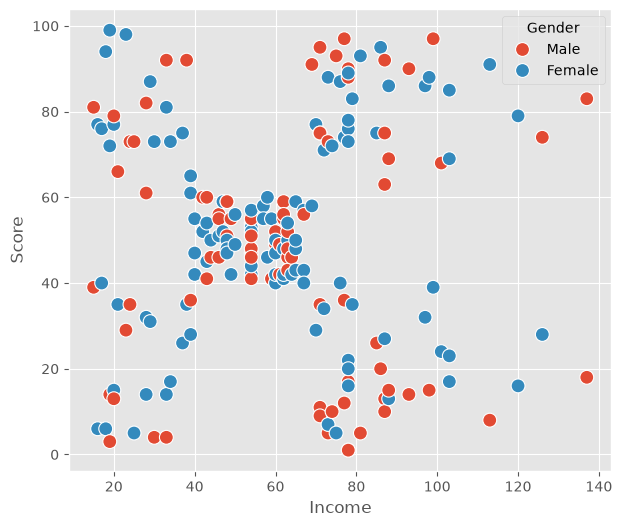

In [16]:
plt.figure(figsize=(7,6))

sns.scatterplot(
    x='Income',
    y='Score',
    hue='Gender',
    data=df,
    s=100
)

plt.show()

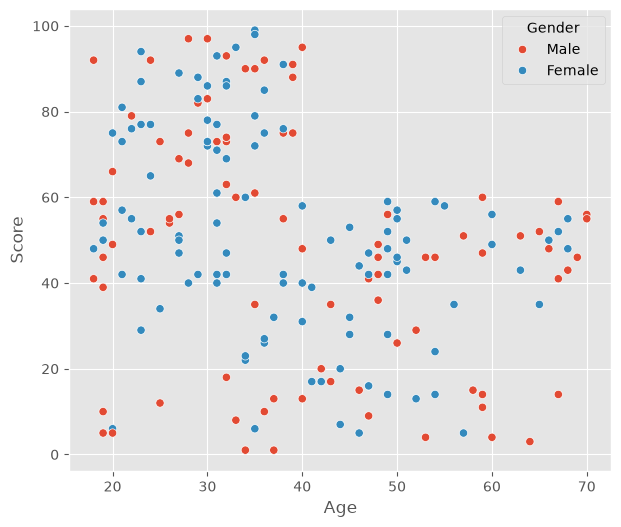

In [17]:
plt.figure(figsize=(7,6))

sns.scatterplot(
    x='Age',
    y='Score',
    hue='Gender',
    data=df
)

plt.show()

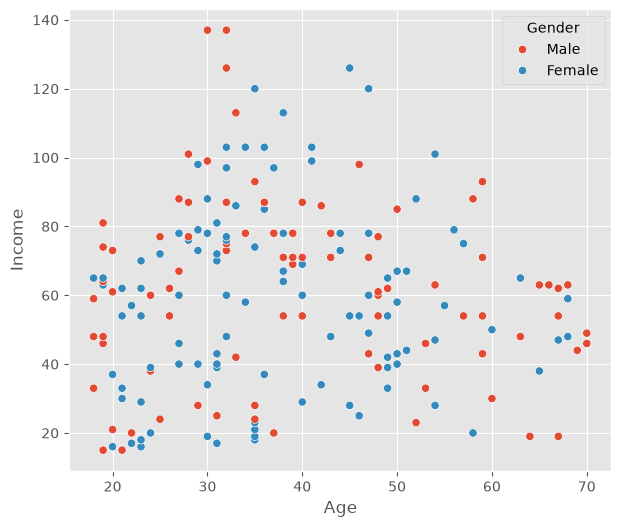

In [18]:
plt.figure(figsize=(7,6))

sns.scatterplot(
    x='Age',
    y='Income',
    hue='Gender',
    data=df
)

plt.show()

**Pairplot**

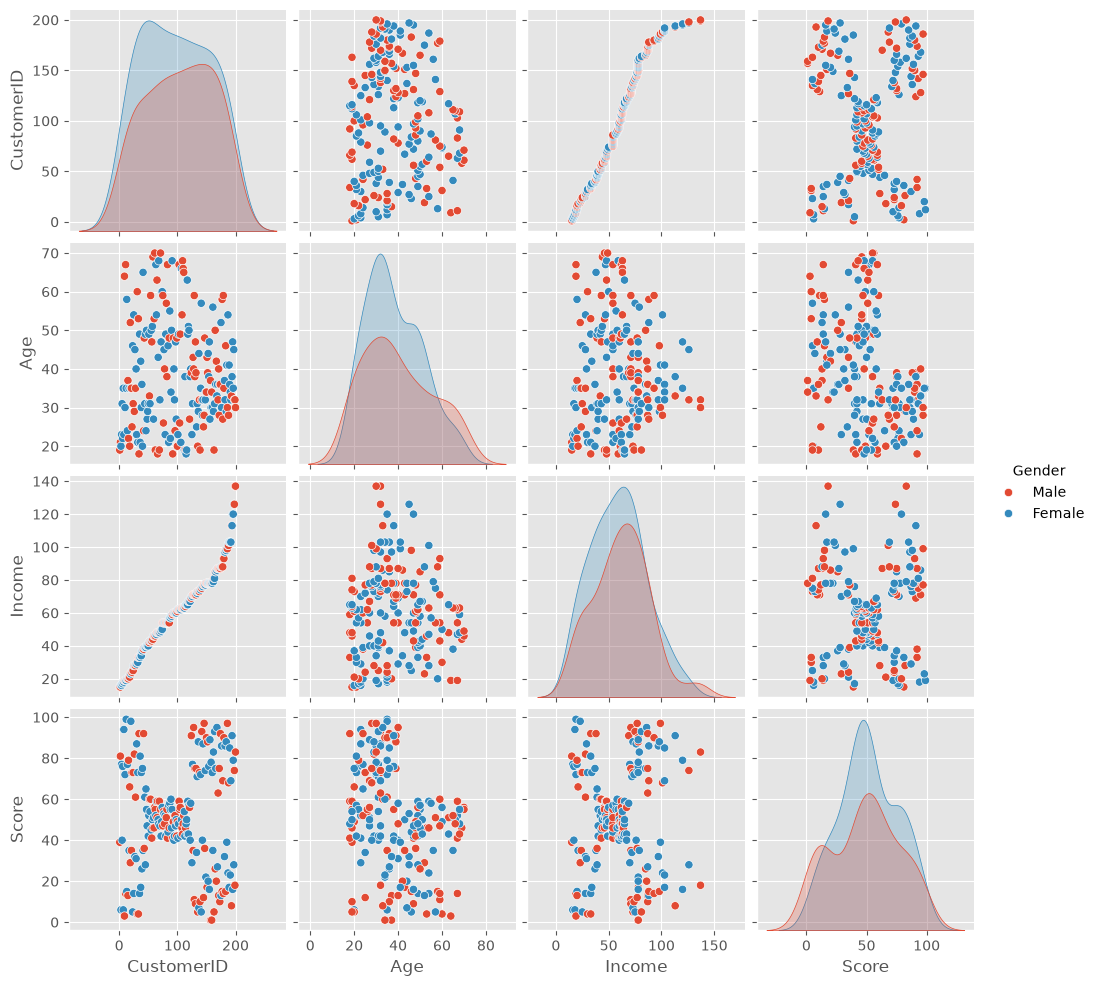

In [19]:
sns.pairplot(df,hue='Gender')

plt.show()

**Correlation** :- Correlation is a statistical measure that describes the relationship between two variables, indicating how they change together. It is quantified using a correlation coefficient (r), which ranges from -1 to 1.
**Positive Correlation (r > 0)**: Both variables move in the same direction (e.g., as a person's height increases, their weight generally increases).
**Negative Correlation (r < 0)**: The variables move in opposite directions (e.g., as the price of an item increases, the demand for it usually decreases).
**No Correlation (r ≈ 0)**: There is no linear relationship or predictable pattern between the variables

In [20]:
numeric_df = df.select_dtypes(include=np.number)

corr = numeric_df.corr()

corr

,CustomerID,Age,Income,Score
CustomerID,1.000000,-0.026763,0.977548,0.013835
Age,-0.026763,1.000000,-0.012398,-0.327227
Income,0.977548,-0.012398,1.000000,0.009903
Score,0.013835,-0.327227,0.009903,1.000000


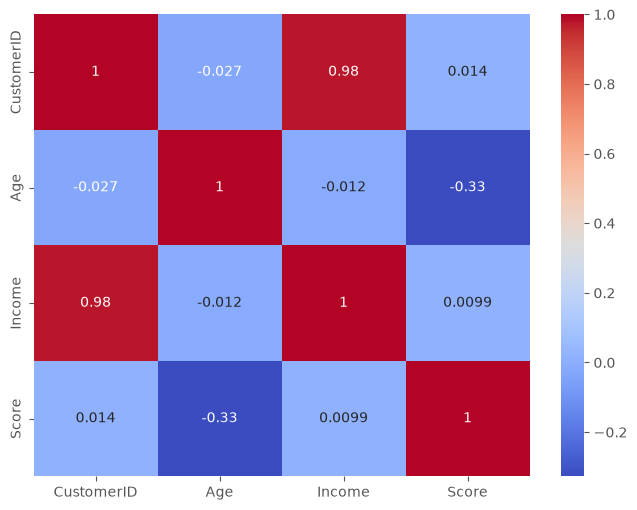

In [21]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.show()

**Average Values**

In [22]:
df.groupby("Gender")[["Income","Score"]].mean()

,Income,Score
Gender,,
Female,59.250000,51.526786
Male,62.227273,48.511364


In [23]:
df.groupby("Gender")[["Age"]].mean()

,Age
Gender,
Female,38.098214
Male,39.806818


**Spending Categories**

In [24]:
df["Category"] = pd.cut(
    df["Score"],
    bins=[0,40,70,100],
    labels=["Low","Medium","High"]
)

df.head()

,CustomerID,Gender,Age,Income,Score,Category
0,1,Male,19,15,39,Low
1,2,Male,21,15,81,High
2,3,Female,20,16,6,Low
3,4,Female,23,16,77,High
4,5,Female,31,17,40,Low


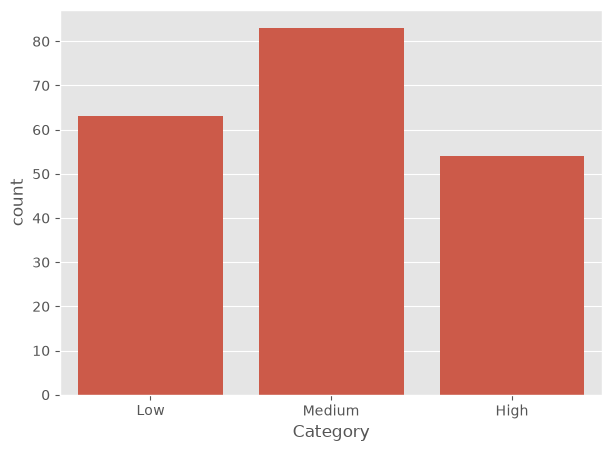

In [25]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df,
    x="Category"
)

plt.show()

**Top Spending Customers**

In [26]:
top = df.sort_values(
    by="Score",
    ascending=False
)

top.head(10)

,CustomerID,Gender,Age,Income,Score,Category
11,12,Female,35,19,99,High
19,20,Female,35,23,98,High
145,146,Male,28,77,97,High
185,186,Male,30,99,97,High
127,128,Male,40,71,95,High
167,168,Female,33,86,95,High
7,8,Female,23,18,94,High
141,142,Male,32,75,93,High
163,164,Female,31,81,93,High
41,42,Male,24,38,92,High


**Income Distribution**

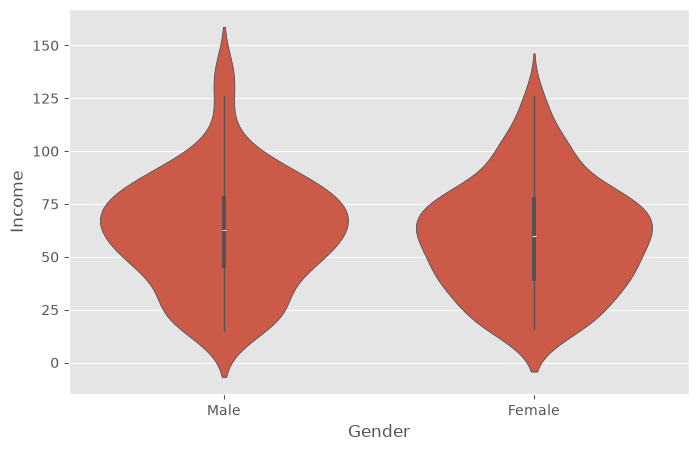

In [27]:
plt.figure(figsize=(8,5))

sns.violinplot(
    x='Gender',
    y='Income',
    data=df
)

plt.show()

**Age Distribution**

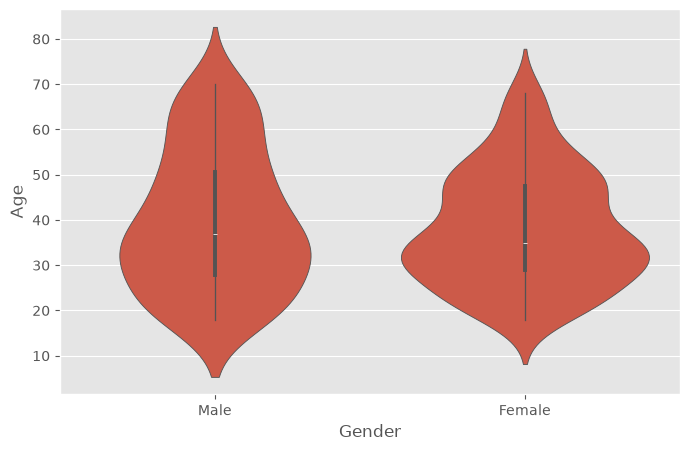

In [28]:
plt.figure(figsize=(8,5))

sns.violinplot(
    x='Gender',
    y='Age',
    data=df
)

plt.show()

**Final Summary**

In [29]:
print("Dataset Shape :",df.shape)

print()

print("Average Income :",df["Income"].mean())

print("Average Spending :",df["Score"].mean())

print("Average Age :",df["Age"].mean())

Dataset Shape : (200, 6)

Average Income : 60.56
Average Spending : 50.2
Average Age : 38.85
